# Advertising Budget and Sales Prediction
### EDA, regression comparison, and residual diagnostics

The supplied dataset relates TV, radio, and newspaper advertising budgets to sales. We compare a linear regression baseline with a random forest using a fixed train/test split. These are associations in this dataset, not causal channel effects; the coefficient interpretation assumes the linear model specification and the data?s units.

In [1]:
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
sns.set_theme(style='whitegrid',palette='colorblind')

In [2]:
df=pd.read_csv(Path('.')/'Advertising Budget and Sales.csv')
df.columns=df.columns.str.strip()
df=df.rename(columns={'TV Ad Budget ($)':'TV','Radio Ad Budget ($)':'Radio','Newspaper Ad Budget ($)':'Newspaper','Sales ($)':'Sales'})
print('Shape:',df.shape)
print('Dtypes:')
print(df.dtypes)
print('Missing values:')
print(df.isna().sum())
display(df.head())
display(df.describe().T)

Shape: (200, 5)
Dtypes:
Unnamed: 0      int64
TV            float64
Radio         float64
Newspaper     float64
Sales         float64
dtype: object
Missing values:
Unnamed: 0    0
TV            0
Radio         0
Newspaper     0
Sales         0
dtype: int64


,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,200.0,100.5000,57.879185,1.0,50.750,100.50,150.250,200.0
TV,200.0,147.0425,85.854236,0.7,74.375,149.75,218.825,296.4
Radio,200.0,23.2640,14.846809,0.0,9.975,22.90,36.525,49.6
Newspaper,200.0,30.5540,21.778621,0.3,12.750,25.75,45.100,114.0
Sales,200.0,14.0225,5.217457,1.6,10.375,12.90,17.400,27.0


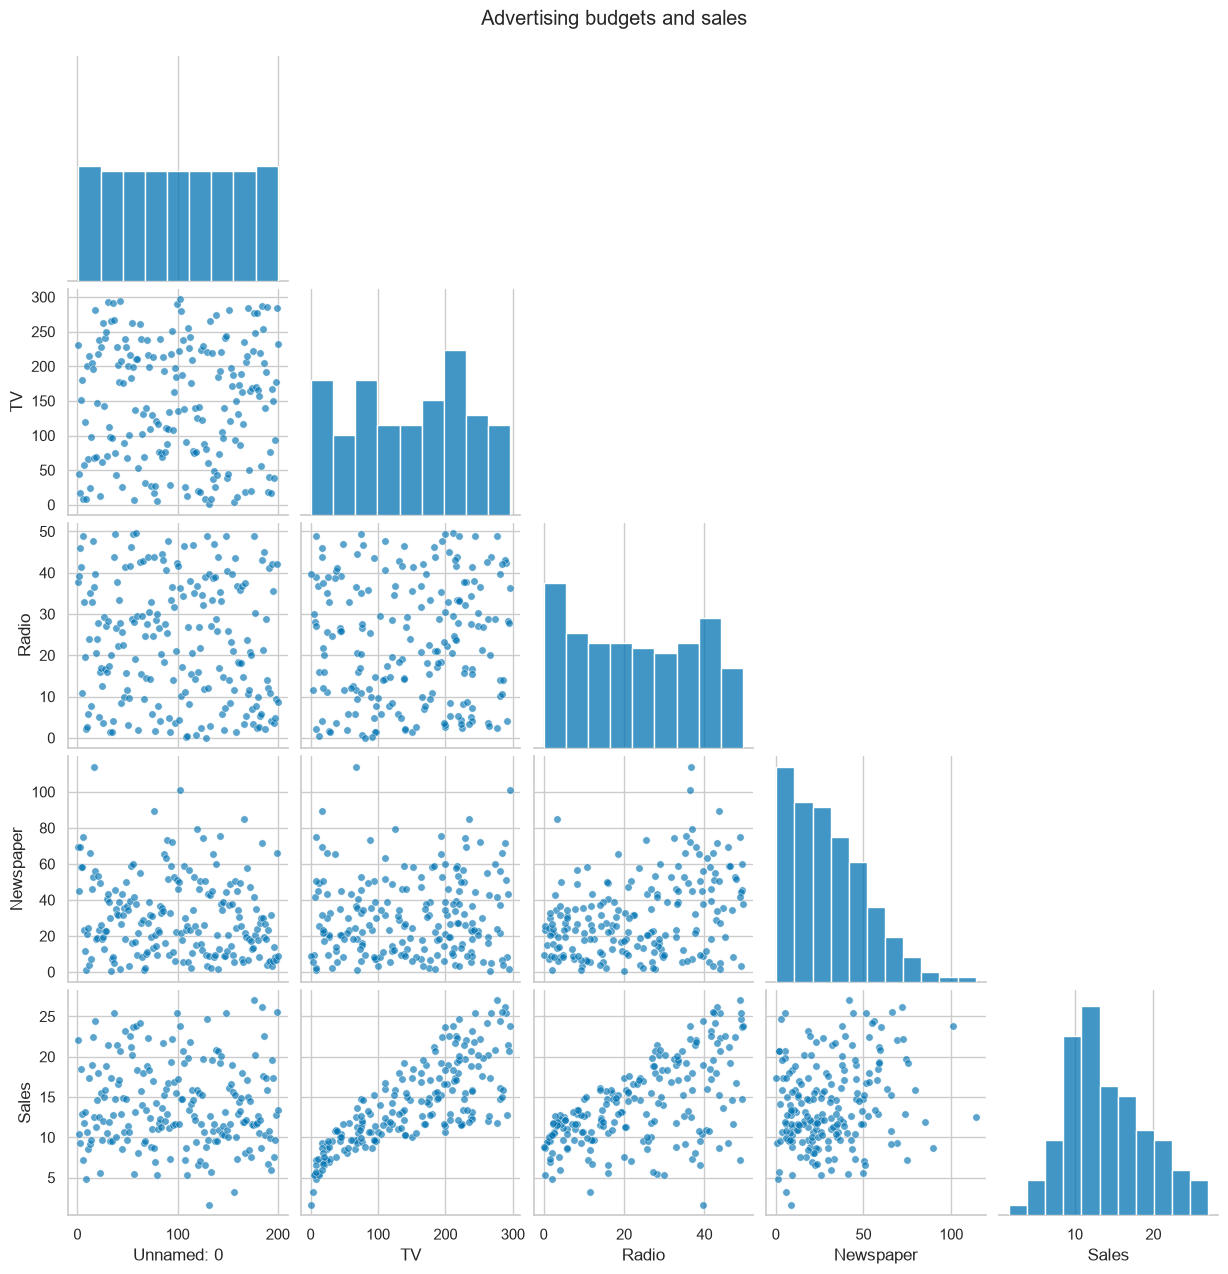

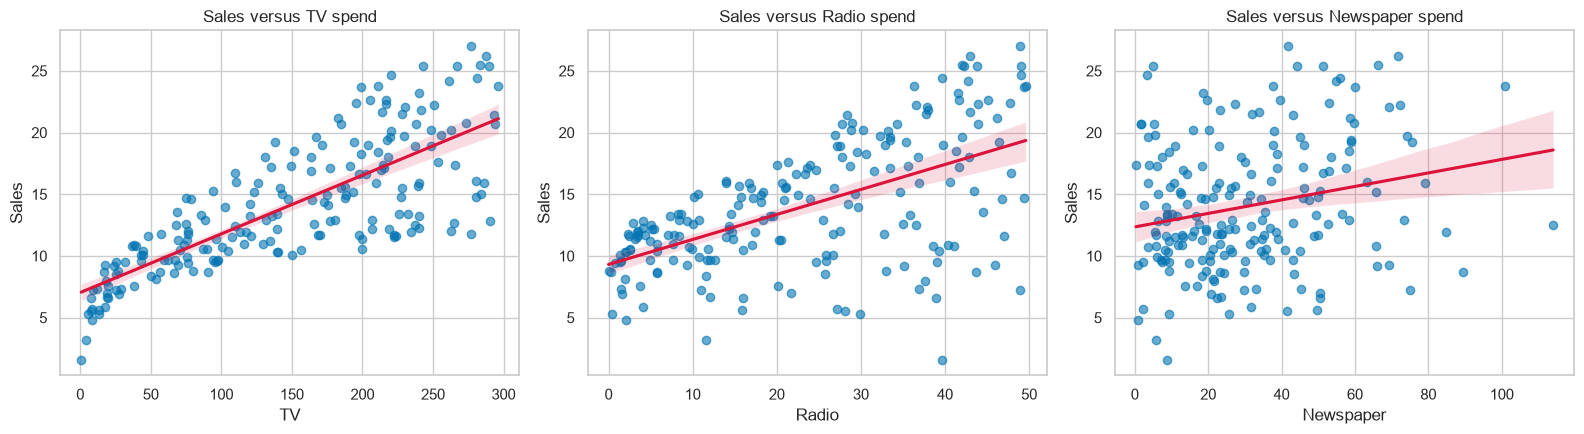

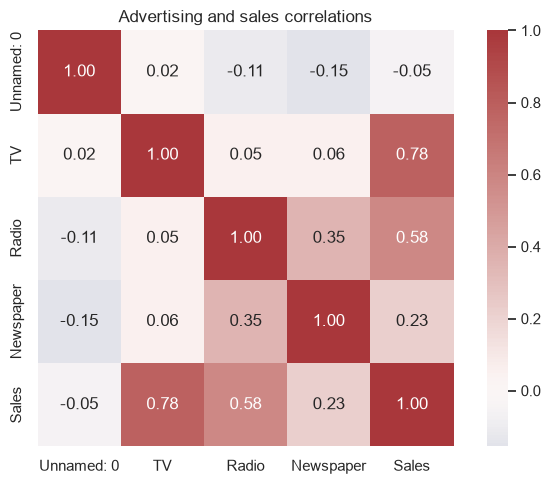

In [3]:
g=sns.pairplot(df,diag_kind='hist',corner=True,plot_kws={'alpha':.65,'s':28}); g.fig.suptitle('Advertising budgets and sales',y=1.02); plt.show()
fig,axes=plt.subplots(1,3,figsize=(16,4.5))
for x,ax in zip(['TV','Radio','Newspaper'],axes):
    sns.regplot(data=df,x=x,y='Sales',ax=ax,scatter_kws={'alpha':.6},line_kws={'color':'crimson'})
    ax.set_title(f'Sales versus {x} spend')
plt.tight_layout(); plt.show()
plt.figure(figsize=(7,5)); sns.heatmap(df.corr(numeric_only=True),annot=True,cmap='vlag',center=0,fmt='.2f',square=True)
plt.title('Advertising and sales correlations'); plt.tight_layout(); plt.show()

The pairplot and individual scatterplots show the strength and shape of each budget-sales relationship. Correlation measures linear association and does not isolate a channel?s effect because budgets may move together. The next cell fits models and prints the linear coefficients for a conditional, unit-based interpretation.

In [4]:
X=df[['TV','Radio','Newspaper']]; y=df['Sales']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,random_state=42)
models={'Linear Regression':make_pipeline(StandardScaler(),LinearRegression()),'Random Forest':RandomForestRegressor(n_estimators=300,min_samples_leaf=2,random_state=42)}
fitted={}; rows=[]
for name,model in models.items():
    model.fit(X_train,y_train); fitted[name]=model; pred=model.predict(X_test)
    rows.append({'Model':name,'MAE':mean_absolute_error(y_test,pred),'RMSE':np.sqrt(mean_squared_error(y_test,pred)),'R2':r2_score(y_test,pred)})
results=pd.DataFrame(rows).sort_values('RMSE'); display(results.round(3))
lin=fitted['Linear Regression'].named_steps['linearregression']
coefficients=pd.Series(lin.coef_,index=X.columns).sort_values(ascending=False)
print('Linear coefficients (change in sales units per one budget unit, conditional on other channels):'); display(coefficients.to_frame('coefficient').round(4))
print('Intercept:',round(lin.intercept_,4))
best_name=results.iloc[0]['Model']; best=fitted[best_name]; best_pred=best.predict(X_test)
print('Selected by lowest test RMSE:',best_name)

,Model,MAE,RMSE,R2
1,Random Forest,0.662,0.791,0.980
0,Linear Regression,1.461,1.782,0.899


Linear coefficients (change in sales units per one budget unit, conditional on other channels):


,coefficient
TV,3.7642
Radio,2.7923
Newspaper,0.0560


Intercept: 14.1
Selected by lowest test RMSE: Random Forest


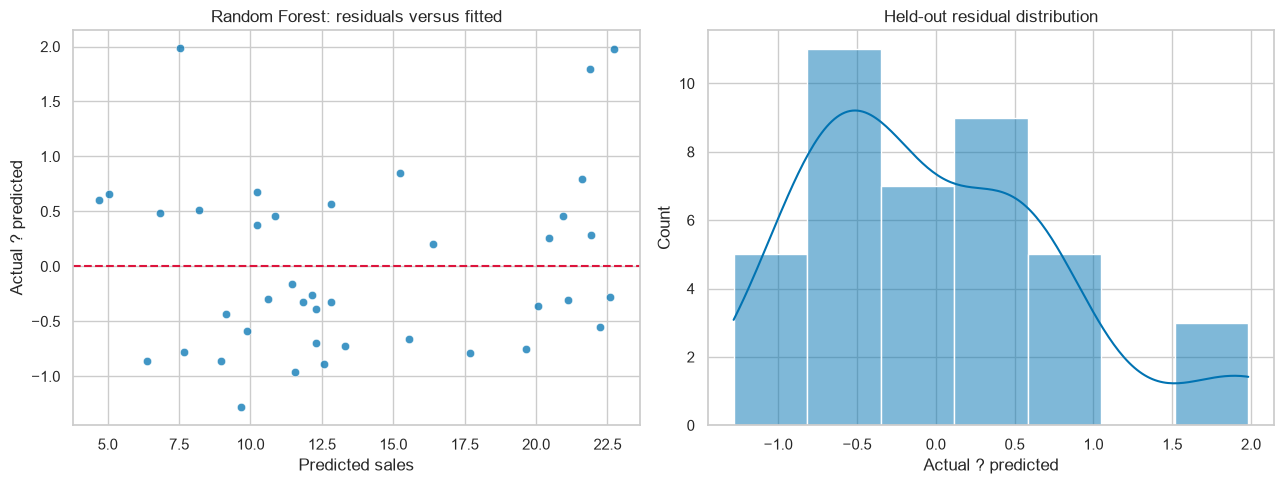

In [5]:
# Residuals versus fitted values: curvature/fanning may indicate systematic errors or unequal variance.
residuals=y_test.to_numpy()-best_pred
fig,axes=plt.subplots(1,2,figsize=(13,5))
sns.scatterplot(x=best_pred,y=residuals,ax=axes[0],alpha=.75); axes[0].axhline(0,color='crimson',linestyle='--')
axes[0].set(title=f'{best_name}: residuals versus fitted',xlabel='Predicted sales',ylabel='Actual ? predicted')
sns.histplot(residuals,kde=True,ax=axes[1]); axes[1].set(title='Held-out residual distribution',xlabel='Actual ? predicted')
plt.tight_layout(); plt.show()

## Conclusion
Use the metric table to compare holdout errors and R?; lower MAE/RMSE and higher R? indicate better fit on this split. Read the residual scatter for a pattern around zero: curvature or a widening spread suggests remaining structure or uneven error variance. In the linear model, compare standardized-feature coefficients to identify the strongest conditional association; because features were standardized before fitting, coefficient magnitudes are per standard deviation. Treat that ranking as predictive evidence, not proof of advertising causality.